In [1]:
import os
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
#Path Defining

DATASET_PATH = Path("../data/raw/UTKFace")

PROCESSED_PATH = Path("../data/processed")
MODELS_PATH = Path("../models")
OUTPUTS_PATH = Path("../outputs")

# Create directories
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)
MODELS_PATH.mkdir(parents=True, exist_ok=True)
OUTPUTS_PATH.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_PATH.resolve())
print("Exists:", DATASET_PATH.exists())
cascade_path = Path("../models/HaarCascade/haarcascade_frontalface_default.xml")
face_cascade = cv2.CascadeClassifier(str(cascade_path))

print("Cascade loaded:", not face_cascade.empty())

Dataset: D:\SPA Project\Gender_Classification\ML Model\Data\Raw\UTKFace
Exists: True
Cascade loaded: True


In [3]:
#Raw Image Data

image_files = list(DATASET_PATH.rglob("*.jpg"))

print("Total JPG images:", len(image_files))

part_counts = Counter(file.parent.name for file in image_files)

print(part_counts)
print(len(image_files))

Total JPG images: 24106
Counter({'part2': 10719, 'part1': 10137, 'part3': 3250})
24106


In [4]:
# File Extensions Check

extensions = Counter(
    file.suffix.lower()
    for file in DATASET_PATH.rglob("*")
    if file.is_file()
)

print(extensions)

Counter({'.jpg': 24106, '': 2, '.pg': 1})


Filename: 100_1_0_20170110183726390.jpg
Shape: (470, 450, 3)


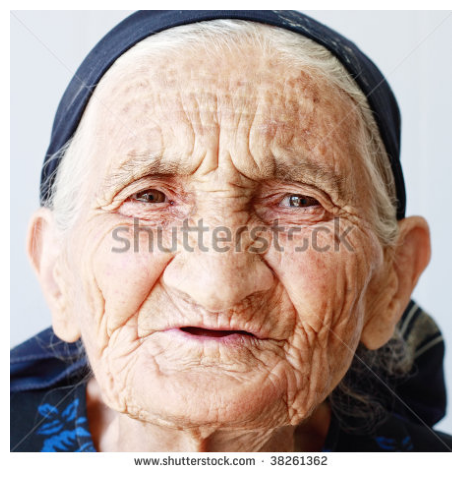

In [5]:
#Raw Image Display
image_file = image_files[0]

image = cv2.imread(str(image_file))

print("Filename:", image_file.name)
print("Shape:", image.shape)

plt.figure(figsize=(6, 6))

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [6]:
#FileName Format
valid_format = []
invalid_format = []

for file in image_files:
    parts = file.stem.split("_")

    if len(parts) == 4:
        valid_format.append(file)
    else:
        invalid_format.append(file)

print("Valid filenames:", len(valid_format))
print("Invalid filenames:", len(invalid_format))

if invalid_format:
    print("Examples of invalid filenames:")

    for file in invalid_format[:10]:
        print(file.name)
else:
    print("All filenames follow the expected format.")

Valid filenames: 24103
Invalid filenames: 3
Examples of invalid filenames:
61_1_20170109142408075.jpg
61_3_20170109150557335.jpg
39_1_20170116174525125.jpg


In [7]:
#Label parsing
records = []

for file in valid_format:
    parts = file.stem.split("_")

    if len(parts) < 4:
        print("Skipping malformed filename:", file.name)
        continue

    try:
        age = int(parts[0])
        gender = int(parts[1])
        race = int(parts[2])
    except ValueError:
        print("Skipping invalid filename:", file.name)
        continue

    records.append({
        "file": str(file),
        "age": age,
        "gender": gender,
        "race": race
    })

Skipping invalid filename: 53__0_20170116184028385.jpg


In [8]:
#Label Validation
metadata = pd.DataFrame(records)

print(metadata["gender"].value_counts())
print("Unique races:", metadata["race"].unique())
print("Minimum age:", metadata["age"].min())
print("Maximum age:", metadata["age"].max())



gender
0    12581
1    11521
Name: count, dtype: int64
Unique races: [0 2 1 3 4]
Minimum age: 1
Maximum age: 116


In [9]:
#Readable Genders
metadata["gender_label"] = metadata["gender"].map({
    0: "Male",
    1: "Female"
})

metadata.head()

,file,age,gender,race,gender_label
0,..\data\raw\UTKFace\part1\100_1_0_201701101837...,100,1,0,Female
1,..\data\raw\UTKFace\part1\100_1_2_201701051748...,100,1,2,Female
2,..\data\raw\UTKFace\part1\100_1_2_201701101828...,100,1,2,Female
3,..\data\raw\UTKFace\part1\101_1_2_201701051747...,101,1,2,Female
4,..\data\raw\UTKFace\part1\10_0_0_2016122022230...,10,0,0,Male


In [10]:
#Saving MetaData
metadata_path = OUTPUTS_PATH / "metadata.csv"

metadata.to_csv(metadata_path, index=False)

print("Metadata saved to:", metadata_path.resolve())

Metadata saved to: D:\SPA Project\Gender_Classification\ML Model\outputs\metadata.csv


In [11]:
#Null Value/Missing Value Check

print(metadata.isnull().sum())

file            0
age             0
gender          0
race            0
gender_label    0
dtype: int64


In [12]:
#File Path Duplicacy
print("Duplicate file Paths:",
      metadata["file"].duplicated().sum())


Duplicate file Paths: 0


gender_label
Male      12581
Female    11521
Name: count, dtype: int64


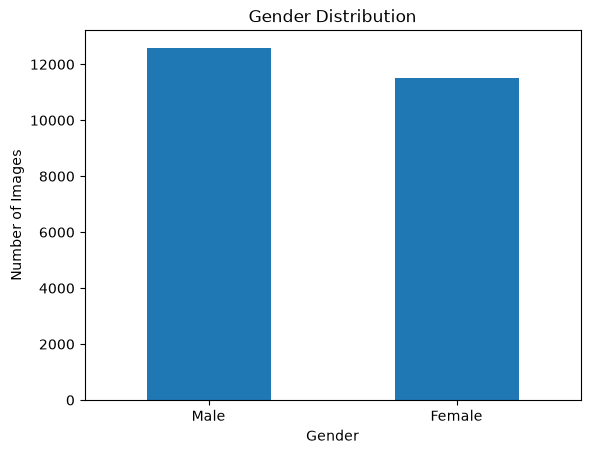

In [13]:
#Gender Distribution

gender_counts = metadata["gender_label"].value_counts()

print(gender_counts)

gender_counts.plot(kind="bar")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

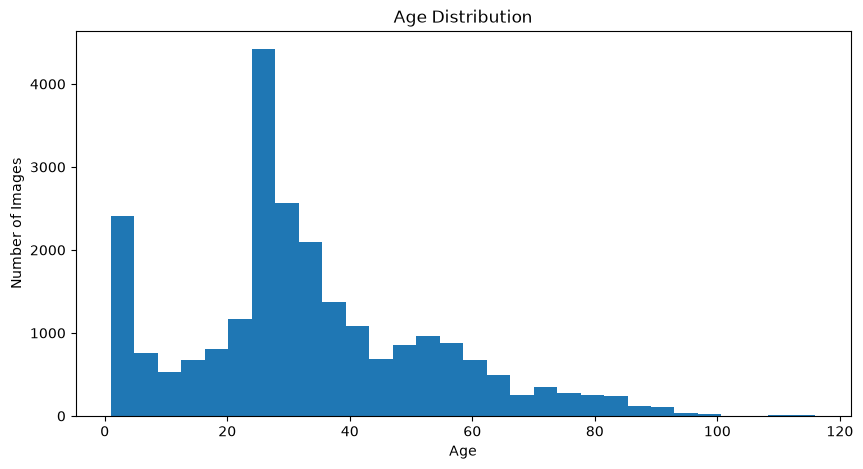

In [14]:
#Age Distrbution
plt.figure(figsize=(10, 5))

plt.hist(metadata["age"], bins=30)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")

plt.show()

In [15]:


def get_dimensions(file):

    image = cv2.imread(str(file))

    if image is not None:
        height, width, channels = image.shape

        return {
            "filename": file.name,
            "path": str(file),
            "width": width,
            "height": height,
            "channels": channels
        }

    return None


with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(executor.map(get_dimensions, image_files))


# Remove images that could not be read
image_dimensions = [
    result for result in results
    if result is not None
]

dimensions_df = pd.DataFrame(image_dimensions)

print("Total image files:", len(image_files))
print("Successfully read:", len(dimensions_df))
print("Unreadable images:", len(image_files) - len(dimensions_df))

print(
    dimensions_df[["width", "height"]]
    .value_counts()
    .head(20)
)

Total image files: 24106
Successfully read: 24106
Unreadable images: 0
width  height
738    1103      659
452    451       544
906    903       520
1106   735       351
368    551       343
1206   675       307
1042   779       274
690    1015      261
782    1039      212
810    1007      178
390    519       175
520    389       166
658    1243      151
552    367       146
602    751       136
240    160       130
404    503       118
1202   675       109
252    251       107
132    165        98
Name: count, dtype: int64


In [16]:
print("Number of images:", len(image_files))

for file in image_files[:5]:
    image = cv2.imread(str(file))

    if image is not None:
        print(file.name, "->", image.shape)
    else:
        print(file.name, "-> FAILED")

Number of images: 24106
100_1_0_20170110183726390.jpg -> (470, 450, 3)
100_1_2_20170105174847679.jpg -> (441, 332, 3)
100_1_2_20170110182836729.jpg -> (680, 488, 3)
101_1_2_20170105174739309.jpg -> (487, 602, 3)
10_0_0_20161220222308131.jpg -> (451, 452, 3)


In [17]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Cascade loaded:",
      not face_cascade.empty())

Cascade loaded: True


In [18]:
valid_images = [
    Path(row["path"])
    for _, row in dimensions_df.iterrows()
]

print("Valid images:", len(valid_images))

Valid images: 24106


In [19]:
test_file = valid_images[0]

image = cv2.imread(str(test_file))

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Faces detected:", len(faces))

Faces detected: 1


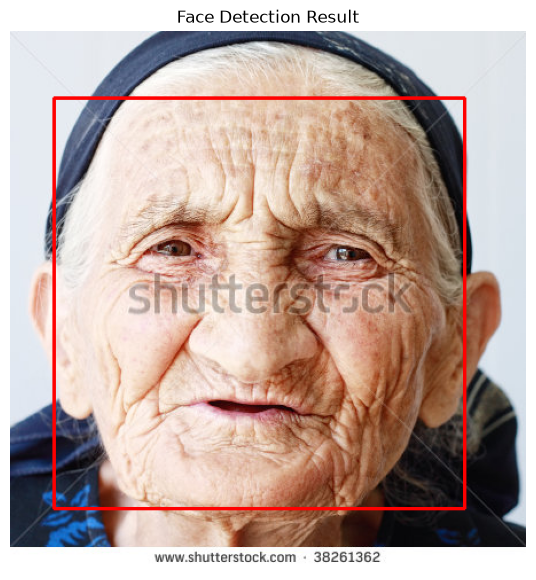

In [20]:
# Displaying the detected face with a bounding box

display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for (x, y, w, h) in faces:
    cv2.rectangle(
        display_image,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

plt.figure(figsize=(7, 7))
plt.imshow(display_image)
plt.title("Face Detection Result")
plt.axis("off")
plt.show()

In [21]:
#cropping the detected face
def detect_and_crop_face(image, face_cascade):
    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(faces) == 0:
        return None

    x, y, w, h = max(
        faces,
        key=lambda face: face[2] * face[3]
    )

    margin = int(0.15 * max(w, h))

    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(image.shape[1], x + w + margin)
    y2 = min(image.shape[0], y + h + margin)

    cropped_face = image[y1:y2, x1:x2]

    if cropped_face.size == 0:
        return None

    return cropped_face

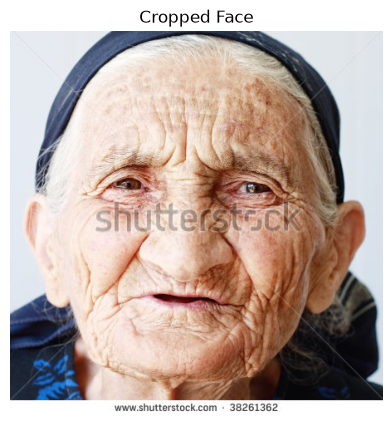

In [22]:
test_file = valid_images[0]

image = cv2.imread(str(test_file))

face = detect_and_crop_face(image, face_cascade)

if face is not None:
    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
    plt.title("Cropped Face")
    plt.axis("off")
    plt.show()
else:
    print("No face detected in:", test_file.name)

Resized image shape: (128, 128, 3)


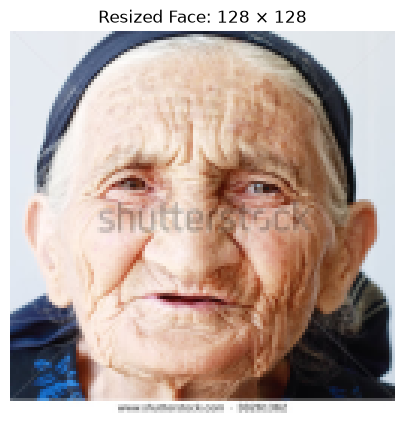

In [23]:
#Resize the image
IMG_SIZE = 128

if face is not None:
    resized_face = cv2.resize(
        face,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )

    print("Resized image shape:", resized_face.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(resized_face, cv2.COLOR_BGR2RGB))
    plt.title("Resized Face: 128 × 128")
    plt.axis("off")
    plt.show()

In [24]:
# Face Detection and Cropping Function

def detect_and_crop_face(image, face_cascade):

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(faces) == 0:
        return None

    # Select the largest detected face
    x, y, w, h = max(
        faces,
        key=lambda face: face[2] * face[3]
    )

    # Add a 15% margin around the face
    margin = int(0.15 * max(w, h))

    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(image.shape[1], x + w + margin)
    y2 = min(image.shape[0], y + h + margin)

    cropped_face = image[y1:y2, x1:x2]

    if cropped_face.size == 0:
        return None

    return cropped_face

In [25]:
# Configuration
IMG_SIZE = 128
CHECKPOINT_INTERVAL = 500

# Save processed images separately from the raw dataset
FACES_PATH = PROCESSED_PATH / "faces_128"
FACES_PATH.mkdir(parents=True, exist_ok=True)

PROCESSED_METADATA_PATH = OUTPUTS_PATH / "processed_metadata.csv"

# Keep a record of every processing attempt
processed_records = []

total = len(metadata)
success_count = 0
failed_read_count = 0
no_face_count = 0
invalid_label_count = 0

for index, row in metadata.iterrows():

    source_path = Path(row["file"])

    # Confirm the label is valid
    gender = int(row["gender"])

    if gender not in (0, 1):
        invalid_label_count += 1
        continue

    # Read the original image
    image = cv2.imread(str(source_path))

    if image is None:
        failed_read_count += 1

        processed_records.append({
            "file": str(source_path),
            "processed_path": None,
            "age": int(row["age"]),
            "gender": gender,
            "gender_label": "Male" if gender == 0 else "Female",
            "race": int(row["race"]),
            "status": "unreadable"
        })
        continue

    # Detect and crop the face
    face = detect_and_crop_face(image, face_cascade)

    if face is None:
        no_face_count += 1

        processed_records.append({8
            "file": str(source_path),
            "processed_path": None,
            "age": int(row["age"]),
            "gender": gender,
            "gender_label": "Male" if gender == 0 else "Female",
            "race": int(row["race"]),
            "status": "no_face_detected"
        })
        continue

    # Resize the cropped face
    resized_face = cv2.resize(
        face,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Preserve source-part folders to avoid filename collisions
    output_folder = FACES_PATH / source_path.parent.name
    output_folder.mkdir(parents=True, exist_ok=True)

    output_path = output_folder / f"{source_path.stem}.jpg"

    # Save the processed image
    saved = cv2.imwrite(str(output_path), resized_face)

    if not saved:
        processed_records.append({
            "file": str(source_path),
            "processed_path": None,
            "age": int(row["age"]),
            "gender": gender,
            "gender_label": "Male" if gender == 0 else "Female",
            "race": int(row["race"]),
            "status": "save_failed"
        })
        continue

    success_count += 1

    processed_records.append({
        "file": str(source_path),
        "processed_path": str(output_path),
        "age": int(row["age"]),
        "gender": gender,
        "gender_label": "Male" if gender == 0 else "Female",
        "race": int(row["race"]),
        "status": "success"
    })

    # Print progress and save checkpoints
    if (index + 1) % CHECKPOINT_INTERVAL == 0:
        pd.DataFrame(processed_records).to_csv(
            PROCESSED_METADATA_PATH,
            index=False
        )

        print(
            f"Processed {index + 1}/{total} | "
            f"Successful: {success_count} | "
            f"No face: {no_face_count} | "
            f"Unreadable: {failed_read_count}"
        )

# Save the final metadata
processed_metadata = pd.DataFrame(processed_records)

processed_metadata.to_csv(
    PROCESSED_METADATA_PATH,
    index=False
)

print("\n--- PREPROCESSING COMPLETE ---")
print("Total metadata records:", total)
print("Records processed:", len(processed_metadata))
print("Successful face crops:", success_count)
print("No face detected:", no_face_count)
print("Unreadable images:", failed_read_count)
print("Invalid labels:", invalid_label_count)
print("Processed images saved to:", FACES_PATH.resolve())
print("Metadata saved to:", PROCESSED_METADATA_PATH.resolve())

Processed 500/24102 | Successful: 468 | No face: 32 | Unreadable: 0
Processed 1000/24102 | Successful: 925 | No face: 75 | Unreadable: 0
Processed 1500/24102 | Successful: 1341 | No face: 159 | Unreadable: 0
Processed 2000/24102 | Successful: 1709 | No face: 291 | Unreadable: 0
Processed 2500/24102 | Successful: 2071 | No face: 429 | Unreadable: 0
Processed 3000/24102 | Successful: 2537 | No face: 463 | Unreadable: 0
Processed 3500/24102 | Successful: 3006 | No face: 494 | Unreadable: 0
Processed 4000/24102 | Successful: 3487 | No face: 513 | Unreadable: 0
Processed 4500/24102 | Successful: 3920 | No face: 580 | Unreadable: 0
Processed 5000/24102 | Successful: 4405 | No face: 595 | Unreadable: 0
Processed 5500/24102 | Successful: 4897 | No face: 603 | Unreadable: 0
Processed 6000/24102 | Successful: 5343 | No face: 657 | Unreadable: 0
Processed 6500/24102 | Successful: 5832 | No face: 668 | Unreadable: 0
Processed 7000/24102 | Successful: 6297 | No face: 703 | Unreadable: 0
Processed 7

In [26]:
print("Processing status:")
print(processed_metadata["status"].value_counts())

print("\nGender distribution among successful crops:")
print(
    processed_metadata.loc[
        processed_metadata["status"] == "success",
        "gender_label"
    ].value_counts()
)

print("\nSample successful records:")
display(
    processed_metadata.loc[
        processed_metadata["status"] == "success"
    ].head()
)

#Checking dimensions for successful records

successful_rows = processed_metadata[
    processed_metadata["status"] == "success"
]

sample_path = Path(successful_rows.iloc[0]["processed_path"])
sample_image = cv2.imread(str(sample_path))

print("Sample image:", sample_path.name)
print("Image shape:", sample_image.shape)

Processing status:
status
success             22355
no_face_detected     1747
Name: count, dtype: int64

Gender distribution among successful crops:
gender_label
Male      11663
Female    10692
Name: count, dtype: int64

Sample successful records:


,file,processed_path,age,gender,gender_label,race,status
0,..\data\raw\UTKFace\part1\100_1_0_201701101837...,..\data\processed\faces_128\part1\100_1_0_2017...,100,1,Female,0,success
1,..\data\raw\UTKFace\part1\100_1_2_201701051748...,..\data\processed\faces_128\part1\100_1_2_2017...,100,1,Female,2,success
2,..\data\raw\UTKFace\part1\100_1_2_201701101828...,..\data\processed\faces_128\part1\100_1_2_2017...,100,1,Female,2,success
3,..\data\raw\UTKFace\part1\101_1_2_201701051747...,..\data\processed\faces_128\part1\101_1_2_2017...,101,1,Female,2,success
4,..\data\raw\UTKFace\part1\10_0_0_2016122022230...,..\data\processed\faces_128\part1\10_0_0_20161...,10,0,Male,0,success


Sample image: 100_1_0_20170110183726390.jpg
Image shape: (128, 128, 3)


In [27]:


# Keep only successfully processed images
usable_data = processed_metadata[
    (processed_metadata["status"] == "success") &
    (processed_metadata["processed_path"].notna())
].copy()

# Confirm gender labels are integers
usable_data["gender"] = usable_data["gender"].astype(int)

# First split: 70% training, 30% temporary
train_data, temp_data = train_test_split(
    usable_data,
    test_size=0.30,
    random_state=42,
    stratify=usable_data["gender"]
)

# Second split: divide temporary data equally
# This produces 15% validation and 15% test overall
val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42,
    stratify=temp_data["gender"]
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Total:", len(train_data) + len(val_data) + len(test_data))

Training images: 15648
Validation images: 3353
Test images: 3354
Total: 22355


In [28]:
for name, split_data in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    print(f"\n{name} set")
    print("Gender counts:")
    print(split_data["gender_label"].value_counts())

    print("\nGender proportions:")
    print(
        split_data["gender_label"]
        .value_counts(normalize=True)
        .round(3)
    )

    


Training set
Gender counts:
gender_label
Male      8164
Female    7484
Name: count, dtype: int64

Gender proportions:
gender_label
Male      0.522
Female    0.478
Name: proportion, dtype: float64

Validation set
Gender counts:
gender_label
Male      1749
Female    1604
Name: count, dtype: int64

Gender proportions:
gender_label
Male      0.522
Female    0.478
Name: proportion, dtype: float64

Test set
Gender counts:
gender_label
Male      1750
Female    1604
Name: count, dtype: int64

Gender proportions:
gender_label
Male      0.522
Female    0.478
Name: proportion, dtype: float64


In [29]:
OUTPUTS_PATH.mkdir(parents=True, exist_ok=True)

train_data.to_csv(
    OUTPUTS_PATH / "train_metadata.csv",
    index=False
)

val_data.to_csv(
    OUTPUTS_PATH / "validation_metadata.csv",
    index=False
)

test_data.to_csv(
    OUTPUTS_PATH / "test_metadata.csv",
    index=False
)

#Checking valid paths and gender references to 0 and 1
print("All three split files saved.")
print("Location:", OUTPUTS_PATH.resolve())

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

print("\nSample training records:")
display(
    train_data[["processed_path", "gender", "gender_label"]].head()
)

All three split files saved.
Location: D:\SPA Project\Gender_Classification\ML Model\outputs
Training: 15648
Validation: 3353
Testing: 3354

Sample training records:


,processed_path,gender,gender_label
20656,..\data\processed\faces_128\part2\77_0_0_20170...,0,Male
21715,..\data\processed\faces_128\part3\26_1_3_20170...,1,Female
14576,..\data\processed\faces_128\part2\28_1_1_20170...,1,Female
8362,..\data\processed\faces_128\part1\65_0_0_20170...,0,Male
15814,..\data\processed\faces_128\part2\31_1_1_20170...,1,Female


In [30]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.float32)

    return image, label


def create_dataset(dataframe, training=False):
    image_paths = dataframe["processed_path"].astype(str).values
    labels = dataframe["gender"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 5000),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_data, training=True)
val_ds = create_dataset(val_data)
test_ds = create_dataset(test_data)

print("TensorFlow datasets created successfully.")


TensorFlow datasets created successfully.


In [31]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Sample labels:", labels[:10].numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Sample labels: [1. 1. 0. 1. 1. 1. 1. 0. 0. 0.]


In [32]:

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODELS_PATH / "best_gender_model.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

MODELS_PATH.mkdir(parents=True, exist_ok=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    
    callbacks=callbacks
)

Epoch 1/15
489/489 ━━━━━━━━━━━━━━━━━━━━ 172s 349ms/step - accuracy: 0.9548 - loss: 0.1052 - val_accuracy: 0.8747 - val_loss: 0.4707
Epoch 2/15
489/489 ━━━━━━━━━━━━━━━━━━━━ 167s 341ms/step - accuracy: 0.9587 - loss: 0.1000 - val_accuracy: 0.8813 - val_loss: 0.4249
Epoch 3/15
489/489 ━━━━━━━━━━━━━━━━━━━━ 145s 297ms/step - accuracy: 0.9618 - loss: 0.0901 - val_accuracy: 0.8822 - val_loss: 0.4923
Epoch 4/15
489/489 ━━━━━━━━━━━━━━━━━━━━ 147s 300ms/step - accuracy: 0.9648 - loss: 0.0870 - val_accuracy: 0.8801 - val_loss: 0.5140
Epoch 5/15
489/489 ━━━━━━━━━━━━━━━━━━━━ 159s 324ms/step - accuracy: 0.9703 - loss: 0.0741 - val_accuracy: 0.8804 - val_loss: 0.5173


In [34]:
import tensorflow as tf

model = tf.keras.models.load_model(
    r"D:\SPA Project\Gender_Classification\ML Model\Notebook\models\recovery_backup.keras"
)

print("Model loaded successfully!")
model.summary()

Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,914,309 (37.82 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,609,540 (25.21 MB)

In [35]:
import tensorflow as tf

backup_path = (
    r"D:\SPA Project\Gender_Classification\ML Model"
    r"\Notebook\models\recovery_backup.keras"
)

checkpoint_path = (
    r"D:\SPA Project\Gender_Classification\ML Model"
    r"\Notebook\models\stalled_run_checkpoint.keras"
)

for name, path in [
    ("Recovery backup", backup_path),
    ("Stalled-run checkpoint", checkpoint_path),
]:
    loaded = tf.keras.models.load_model(path)

    print(f"\n{name}")
    print("Optimizer iterations:", loaded.optimizer.iterations.numpy())
    print("Input shape:", loaded.input_shape)
    print("Output shape:", loaded.output_shape)


Recovery backup
Optimizer iterations: 3912
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)

Stalled-run checkpoint
Optimizer iterations: 3912
Input shape: (None, 128, 128, 3)
Output shape: (None, 1)


print("Completed epochs:", len(history.history["loss"]))
print("Training accuracy:", history.history["accuracy"])
print("Validation accuracy:", history.history["val_accuracy"])
print("Optimizer iterations:", model.optimizer.iterations.numpy())